
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


In [1]:
import pandas as pd

path = 'UCI HAR Dataset/UCI HAR Dataset/'

# названия 561 признака (42 названия повторяются, поэтому добавляем к повторам _1, _2)
features = pd.read_csv(path + 'features.txt', sep=r'\s+', header=None)[1]
counts = features.groupby(features).cumcount()
names = features.where(counts == 0, features + '_' + counts.astype(str))

# признаки и метки (train и test)
X_train = pd.read_csv(path + 'train/X_train.txt', sep=r'\s+', header=None, names=names)
X_test  = pd.read_csv(path + 'test/X_test.txt',  sep=r'\s+', header=None, names=names)
y_train = pd.read_csv(path + 'train/y_train.txt', header=None)[0]
y_test  = pd.read_csv(path + 'test/y_test.txt',  header=None)[0]

# номера 1..6 превращаем в названия действий
labels = pd.read_csv(path + 'activity_labels.txt', sep=r'\s+', header=None, index_col=0)[1]

# объединяем всё в одну таблицу и сохраняем
data = pd.concat([X_train, X_test], ignore_index=True)
data['Activity'] = pd.concat([y_train, y_test], ignore_index=True).map(labels)
data.to_csv('Human_Activity_Recognition_Using_Smartphones_Data.csv', index=False)


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [2]:
import pandas as pd

# 1. Загрузка файла
df = pd.read_csv('Human_Activity_Recognition_Using_Smartphones_Data.csv')

# 2. Размерности и типы данных
print('Размерность:', df.shape)
print(df.dtypes.value_counts())

# 3. Первые 5 строк и пропущенные значения
display(df.head())
print('Всего пропущенных значений:', df.isnull().sum().sum())


Размерность: (10299, 562)
float64    561
object       1
Name: count, dtype: int64


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


Всего пропущенных значений: 0



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

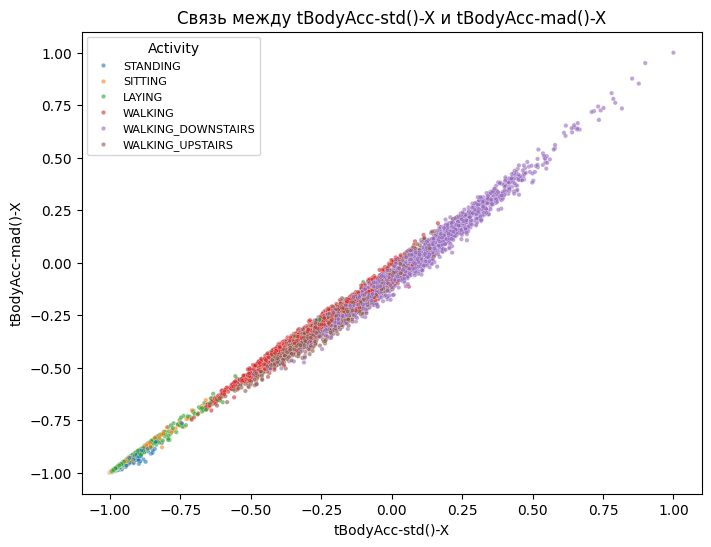

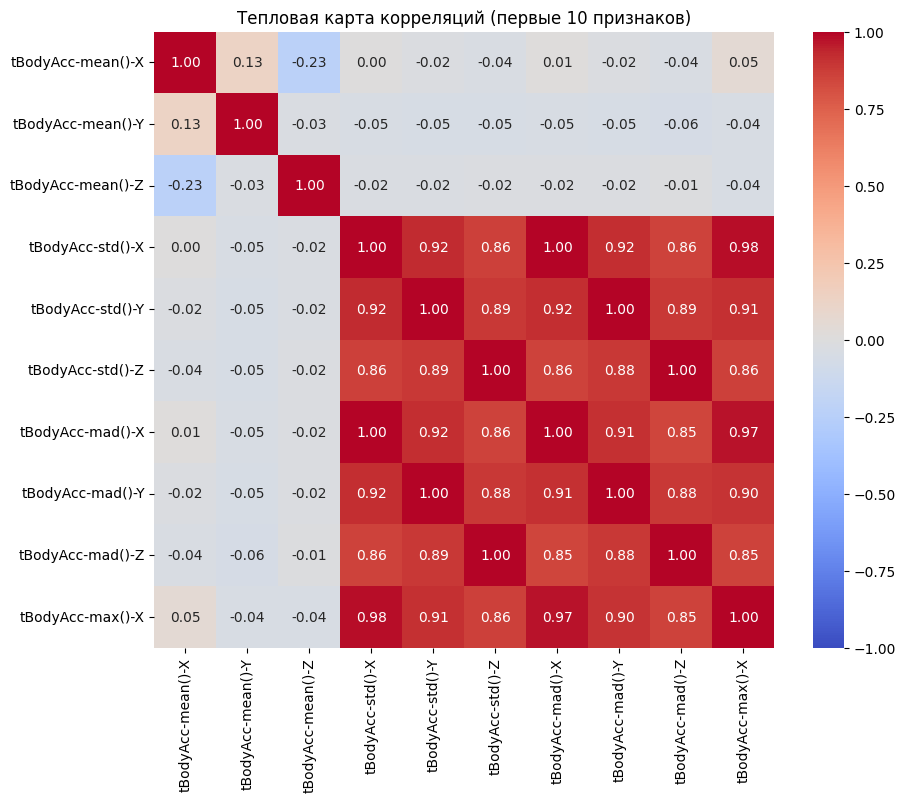

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Точечная диаграмма: связь между двумя числовыми признаками
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='tBodyAcc-std()-X', y='tBodyAcc-mad()-X',
                hue='Activity', s=10, alpha=0.6)
plt.title('Связь между tBodyAcc-std()-X и tBodyAcc-mad()-X')
plt.xlabel('tBodyAcc-std()-X')
plt.ylabel('tBodyAcc-mad()-X')
plt.legend(title='Activity', fontsize=8)
plt.show()

# 2. Тепловая карта корреляций (первые 10 признаков, т.к. всего их 561)
corr = df.iloc[:, :10].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Тепловая карта корреляций (первые 10 признаков)')
plt.show()


## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Признаки (X) и цель (y): только числовые столбцы
X_reg = df.drop(columns=['Activity', 'tBodyAcc-mean()-X'])
y_reg = df['tBodyAcc-mean()-X']

# 1. Разделение 80% / 20%
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

print('Обучающая выборка:', X_train_r.shape)
print('Тестовая выборка:', X_test_r.shape)

# 2. Модель линейной регрессии
lin_reg = LinearRegression()
lin_reg.fit(X_train_r, y_train_r)
y_pred_r = lin_reg.predict(X_test_r)

# 3. Метрики
mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)

print(f'MAE:  {mae:.4f}')
print(f'MSE:  {mse:.4f}')
print(f'RMSE: {rmse:.4f}')


Обучающая выборка: (8239, 560)
Тестовая выборка: (2060, 560)
MAE:  0.0232
MSE:  0.0015
RMSE: 0.0393



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [5]:
# 1. Импорт scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Признаки и цель для классификации
X = df.drop(columns=['Activity'])
y = df['Activity']

# 2. Разделение 80% / 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Кросс-валидация KNN (5 фолдов) на обучающей выборке
knn = KNeighborsClassifier(n_neighbors=5)
scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')

print('Accuracy по фолдам:', scores.round(4))
print(f'Средняя accuracy: {scores.mean():.4f} (± {scores.std():.4f})')

# Дополнительно: проверка на тестовой выборке
knn.fit(X_train, y_train)
print(f'Accuracy на тесте: {knn.score(X_test, y_test):.4f}')


Accuracy по фолдам: [0.9684 0.9636 0.966  0.966  0.9654]
Средняя accuracy: 0.9659 (± 0.0016)
Accuracy на тесте: 0.9646



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [6]:
from sklearn.metrics import r2_score

# Линейная регрессия: предсказываем tBodyAcc-mean()-X по остальным признакам
y_pred_lin = lin_reg.predict(X_test_r)

print(f'R² на тесте: {r2_score(y_test_r, y_pred_lin):.4f}')
print(f'MAE: {mean_absolute_error(y_test_r, y_pred_lin):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_lin)):.4f}')


R² на тесте: 0.6880
MAE: 0.0232
RMSE: 0.0393


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Бинарная цель: 1 — движение, 0 — покой
y_bin = y.isin(['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS']).astype(int)
print(y_bin.value_counts())

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X, y_bin, test_size=0.2, random_state=42, stratify=y_bin)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_b, y_train_b)
y_pred_b = log_reg.predict(X_test_b)

print(f'Accuracy: {accuracy_score(y_test_b, y_pred_b):.4f}')
print(classification_report(y_test_b, y_pred_b, target_names=['Покой', 'Движение']))


Activity
0    5627
1    4672
Name: count, dtype: int64
Accuracy: 1.0000
              precision    recall  f1-score   support

       Покой       1.00      1.00      1.00      1126
    Движение       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [8]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf')
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print(f'Accuracy SVM: {accuracy_score(y_test, y_pred_svm):.4f}')
print(classification_report(y_test, y_pred_svm))


Accuracy SVM: 0.9757
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.93      0.95      0.94       356
          STANDING       0.95      0.93      0.94       381
           WALKING       1.00      1.00      1.00       344
WALKING_DOWNSTAIRS       0.99      0.99      0.99       281
  WALKING_UPSTAIRS       0.99      0.99      0.99       309

          accuracy                           0.98      2060
         macro avg       0.98      0.98      0.98      2060
      weighted avg       0.98      0.98      0.98      2060



## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

Accuracy: 0.9864


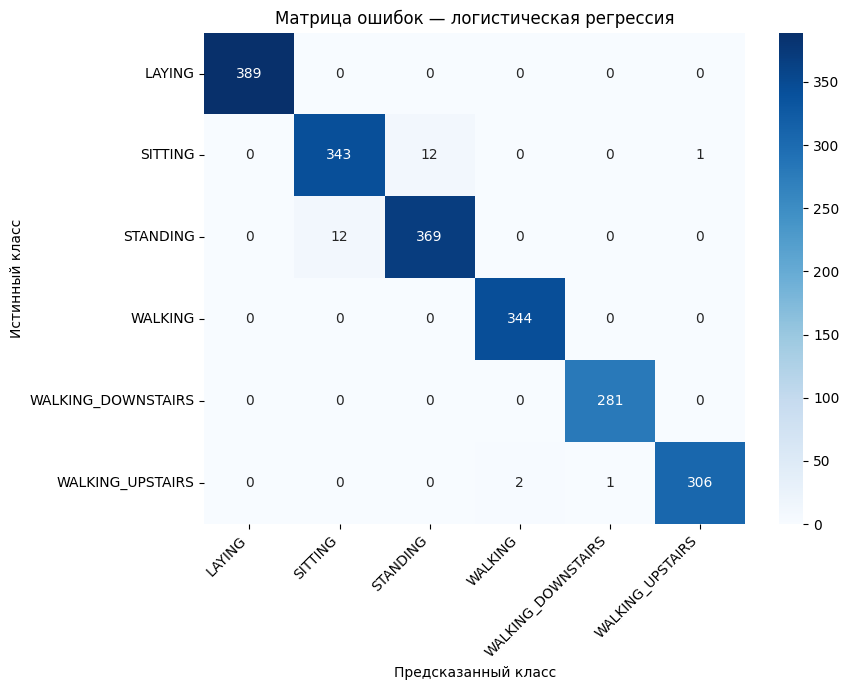

In [9]:
from sklearn.metrics import confusion_matrix

# 1. Логистическая классификация (6 классов)
log_reg_multi = LogisticRegression(max_iter=2000)
log_reg_multi.fit(X_train, y_train)
y_pred_lr = log_reg_multi.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}')

# 2. Матрица ошибок и её отображение через Seaborn
classes = log_reg_multi.classes_
cm = confusion_matrix(y_test, y_pred_lr, labels=classes)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('Матрица ошибок — логистическая регрессия')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

Найденное θ: 1.0080
Итоговая стоимость J: 0.001605
Точное θ:    1.0080


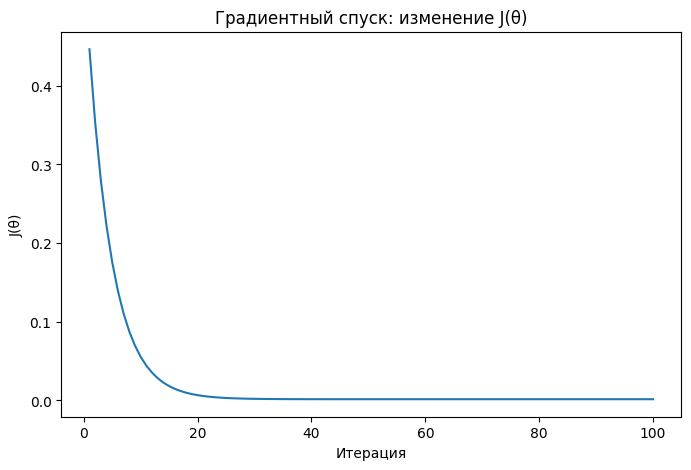

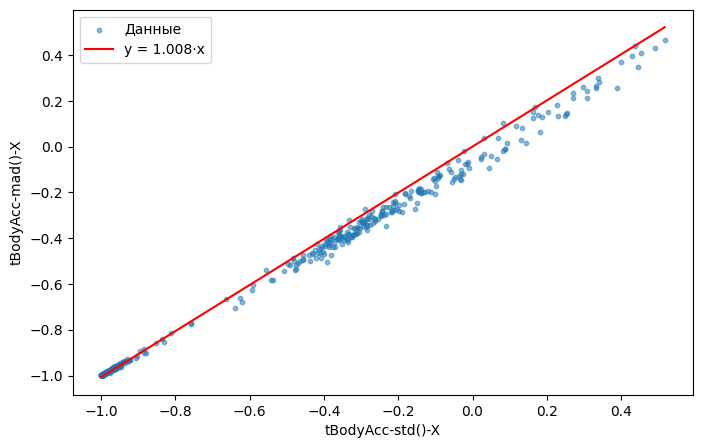

In [ ]:
# Подмножество данных
subset = df.sample(500, random_state=42)
x = subset['tBodyAcc-std()-X'].values
y_gd = subset['tBodyAcc-mad()-X'].values

# Функция стоимости и её производная
def cost(theta, x, y):
    return np.mean((theta * x - y) ** 2)

def gradient(theta, x, y):
    return 2 * np.mean((theta * x - y) * x)

# Градиентный спуск
theta = 0.0
learning_rate = 0.1
n_iter = 100
history = []

for i in range(n_iter):
    theta = theta - learning_rate * gradient(theta, x, y_gd)
    history.append(cost(theta, x, y_gd))

print(f'Найденное θ: {theta:.4f}')
print(f'Итоговая стоимость J: {history[-1]:.6f}')

# Проверка: точное аналитическое решение θ = Σxy / Σx²
theta_exact = np.sum(x * y_gd) / np.sum(x ** 2)
print(f'Точное θ:    {theta_exact:.4f}')

# График уменьшения функции стоимости
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_iter + 1), history)
plt.title('Градиентный спуск: изменение J(θ)')
plt.xlabel('Итерация')
plt.ylabel('J(θ)')
plt.show()

# График: данные и найденная прямая y = θx
plt.figure(figsize=(8, 5))
plt.scatter(x, y_gd, s=10, alpha=0.5, label='Данные')
x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, theta * x_line, color='red', label=f'y = {theta:.3f}·x')
plt.xlabel('tBodyAcc-std()-X')
plt.ylabel('tBodyAcc-mad()-X')
plt.legend()
plt.show()


## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Accuracy Random Forest: 0.9816
tGravityAcc-mean()-X                 0.034153
angle(X,gravityMean)                 0.033946
tGravityAcc-max()-X                  0.028654
tGravityAcc-energy()-X               0.023625
tGravityAcc-mean()-Y                 0.023182
tGravityAcc-min()-X                  0.022437
tGravityAcc-min()-Y                  0.021886
tGravityAcc-max()-Y                  0.021804
angle(Y,gravityMean)                 0.017494
fBodyAccJerk-bandsEnergy()-1,16_1    0.014317
dtype: float64


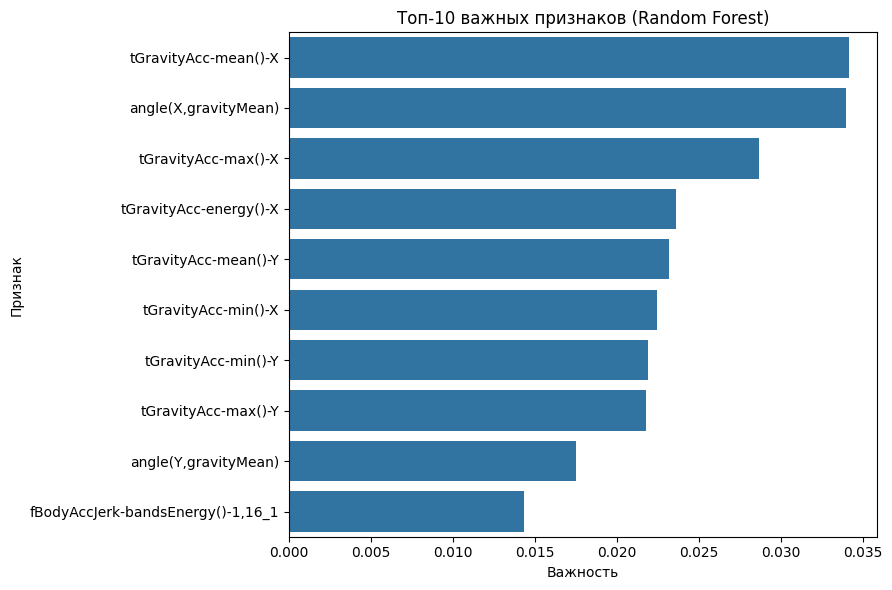

In [11]:
from sklearn.ensemble import RandomForestClassifier

# 3. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(f'Accuracy Random Forest: {accuracy_score(y_test, y_pred_rf):.4f}')

# Важность признаков: топ-10
importances = pd.Series(rf.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)
print(top10)

plt.figure(figsize=(9, 6))
sns.barplot(x=top10.values, y=top10.index)
plt.title('Топ-10 важных признаков (Random Forest)')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()
plt.show(
)


Accuracy AdaBoost: 0.9743
Accuracy Bagging:  0.9660


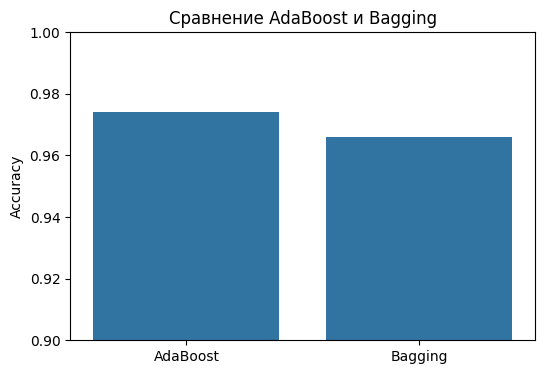

In [12]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# 4. Бустинг: AdaBoost
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                         n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
acc_ada = accuracy_score(y_test, ada.predict(X_test))

# Бэггинг: Bagging
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=50, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
acc_bag = accuracy_score(y_test, bag.predict(X_test))

print(f'Accuracy AdaBoost: {acc_ada:.4f}')
print(f'Accuracy Bagging:  {acc_bag:.4f}')

# Сравнение на графике
plt.figure(figsize=(6, 4))
sns.barplot(x=['AdaBoost', 'Bagging'], y=[acc_ada, acc_bag])
plt.ylim(0.9, 1.0)
plt.title('Сравнение AdaBoost и Bagging')
plt.ylabel('Accuracy')
plt.show()


## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

Accuracy Stacking: 0.9888
KNN                    0.9646
Bagging                0.9660
AdaBoost               0.9743
SVM                    0.9757
Random Forest          0.9816
Logistic Regression    0.9864
Stacking               0.9888
dtype: float64


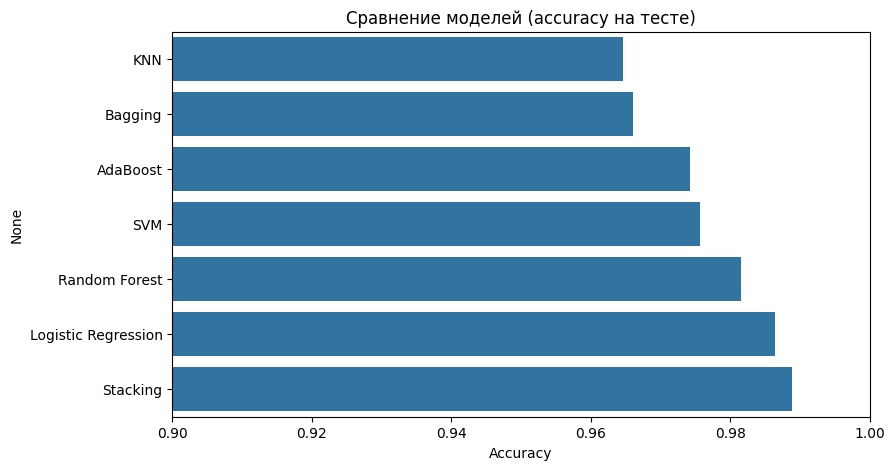

In [13]:
from sklearn.ensemble import StackingClassifier

# 1. Базовые модели: Random Forest, SVM, логистическая регрессия
base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ('svm', SVC(kernel='rbf', probability=True, random_state=42)),
    ('lr', LogisticRegression(max_iter=2000))
]

# 2. Мета-модель: логистическая регрессия
stacking = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3,
    n_jobs=-1
)

stacking.fit(X_train, y_train)
y_pred_stack = stacking.predict(X_test)

# 3. Итоговая точность на тесте
acc_stack = accuracy_score(y_test, y_pred_stack)
print(f'Accuracy Stacking: {acc_stack:.4f}')

# Сравнение всех моделей классификации (6 классов)
results = pd.Series({
    'KNN': knn.score(X_test, y_test),
    'SVM': accuracy_score(y_test, y_pred_svm),
    'Logistic Regression': accuracy_score(y_test, y_pred_lr),
    'Random Forest': accuracy_score(y_test, y_pred_rf),
    'AdaBoost': acc_ada,
    'Bagging': acc_bag,
    'Stacking': acc_stack
}).sort_values()

print(results.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(x=results.values, y=results.index)
plt.xlim(0.9, 1.0)
plt.title('Сравнение моделей (accuracy на тесте)')
plt.xlabel('Accuracy')
plt.show()



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
